In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

data_path = Path("../data/raw/ludhiana_rainfall_reference_2022_2025.csv")

if not data_path.exists():
    data_path = Path("data/raw/ludhiana_rainfall_reference_2022_2025.csv")

analysis_df = pd.read_csv(data_path)
analysis_df["date"] = pd.to_datetime(analysis_df["date"])
analysis_df = analysis_df.sort_values("date").reset_index(drop=True)

print("DATA LOADED FOR ANALYSIS")
print("-" * 35)
print("Rows:", len(analysis_df))
print("Date range:", analysis_df["date"].min().date(), "to", analysis_df["date"].max().date())
print("Missing values:", analysis_df.isna().sum().sum())
print("\nRainfall summary (mm):")
print(analysis_df["observed_rainfall_mm"].describe().round(2).to_string())

print("\nMonthly average rainfall (mm):")
print(
    analysis_df.assign(month=analysis_df["date"].dt.month)
    .groupby("month")["observed_rainfall_mm"]
    .mean()
    .round(2)
    .to_string()
)


DATA LOADED FOR ANALYSIS
-----------------------------------
Rows: 1461
Date range: 2022-01-01 to 2025-12-31
Missing values: 0

Rainfall summary (mm):
count    1461.00
mean        2.07
std         6.43
min         0.00
25%         0.00
50%         0.00
75%         0.70
max        75.60

Monthly average rainfall (mm):
month
1     1.57
2     1.35
3     1.15
4     0.47
5     1.46
6     1.95
7     6.45
8     5.24
9     3.73
10    0.70
11    0.24
12    0.44


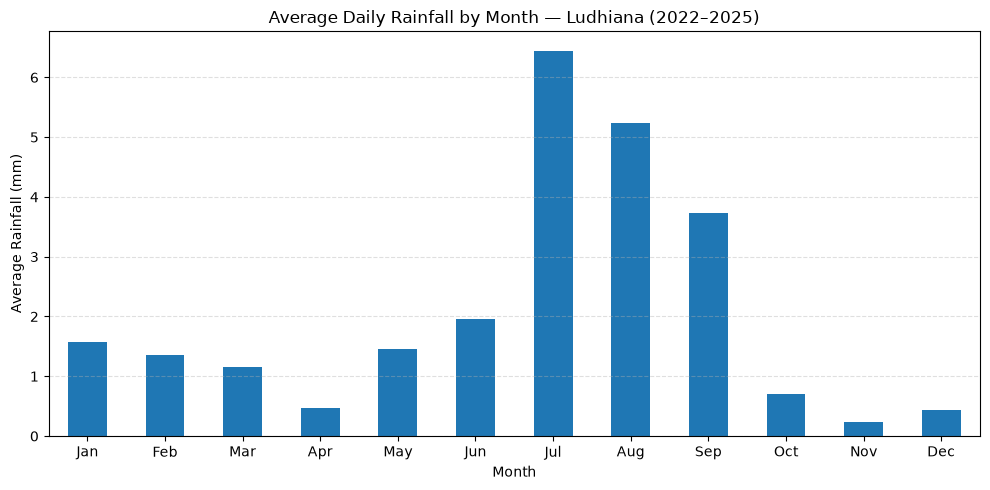

Wettest month: 7
Highest monthly average: 6.45 mm/day
Driest month: 11
Lowest monthly average: 0.24 mm/day


In [2]:

monthly_rainfall = (
    analysis_df.assign(month=analysis_df["date"].dt.month)
    .groupby("month")["observed_rainfall_mm"]
    .mean()
)

plt.figure(figsize=(10, 5))
monthly_rainfall.plot(kind="bar")
plt.title("Average Daily Rainfall by Month — Ludhiana (2022–2025)")
plt.xlabel("Month")
plt.ylabel("Average Rainfall (mm)")
plt.xticks(
    ticks=range(12),
    labels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
            "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Wettest month:", monthly_rainfall.idxmax())
print(f"Highest monthly average: {monthly_rainfall.max():.2f} mm/day")
print("Driest month:", monthly_rainfall.idxmin())
print(f"Lowest monthly average: {monthly_rainfall.min():.2f} mm/day")


In [3]:

# STEP 48 — Count rainy and dry days

rain_threshold = 0.1  # Rainfall below 0.1 mm is considered dry

analysis_df["rain_status"] = analysis_df["observed_rainfall_mm"].apply(
    lambda rainfall: "Rainy Day" if rainfall >= rain_threshold else "Dry Day"
)

rain_counts = analysis_df["rain_status"].value_counts()
rain_percentages = (
    analysis_df["rain_status"].value_counts(normalize=True) * 100
)

print("RAINY DAYS VS DRY DAYS")
print("-" * 35)

for status in ["Rainy Day", "Dry Day"]:
    print(
        f"{status}: {rain_counts.get(status, 0)} days "
        f"({rain_percentages.get(status, 0):.2f}%)"
    )

print("\nTotal days:", len(analysis_df))


RAINY DAYS VS DRY DAYS
-----------------------------------
Rainy Day: 521 days (35.66%)
Dry Day: 940 days (64.34%)

Total days: 1461


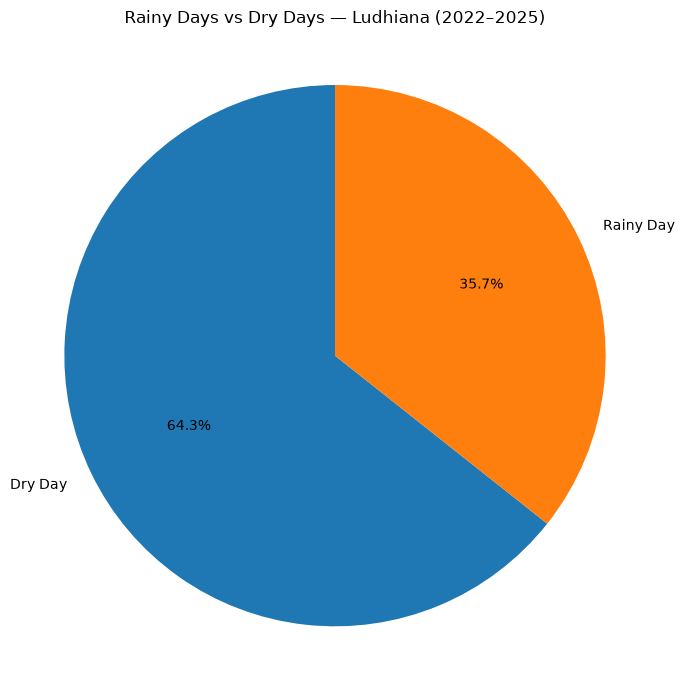

In [4]:

# STEP 49 — Visualize rainy and dry days

rain_counts = analysis_df["rain_status"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    rain_counts,
    labels=rain_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Rainy Days vs Dry Days — Ludhiana (2022–2025)")
plt.axis("equal")
plt.tight_layout()
plt.show()


In [5]:

# STEP 50 — Analyze rainfall intensity

def classify_rainfall(mm):
    if mm < 0.1:
        return "Dry"
    elif mm < 2.5:
        return "Light"
    elif mm < 15:
        return "Moderate"
    elif mm < 64.5:
        return "Heavy"
    else:
        return "Very Heavy"

analysis_df["rainfall_category"] = analysis_df["observed_rainfall_mm"].apply(
    classify_rainfall
)

intensity_counts = (
    analysis_df["rainfall_category"]
    .value_counts()
    .reindex(["Dry", "Light", "Moderate", "Heavy", "Very Heavy"], fill_value=0)
)

print("RAINFALL INTENSITY ANALYSIS")
print("-" * 40)

for category, count in intensity_counts.items():
    print(f"{category}: {count} days ({count / len(analysis_df) * 100:.2f}%)")

print("\nMaximum recorded daily rainfall:",
      analysis_df["observed_rainfall_mm"].max(), "mm")


RAINFALL INTENSITY ANALYSIS
----------------------------------------
Dry: 940 days (64.34%)
Light: 292 days (19.99%)
Moderate: 170 days (11.64%)
Heavy: 57 days (3.90%)
Very Heavy: 2 days (0.14%)

Maximum recorded daily rainfall: 75.6 mm


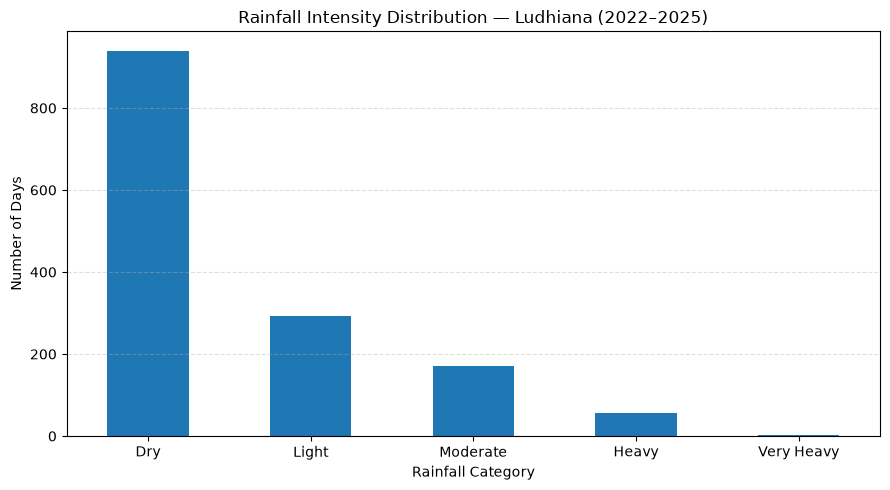

In [6]:

# STEP 51 — Visualize rainfall intensity distribution

plt.figure(figsize=(9, 5))

intensity_counts.plot(kind="bar")

plt.title("Rainfall Intensity Distribution — Ludhiana (2022–2025)")
plt.xlabel("Rainfall Category")
plt.ylabel("Number of Days")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


YEARLY RAINFALL ANALYSIS
---------------------------------------------
      total_rainfall_mm  average_daily_rainfall_mm  rainy_days
year                                                          
2022              872.9                       2.39         127
2023              739.9                       2.03         140
2024              511.1                       1.40         116
2025              904.5                       2.48         138


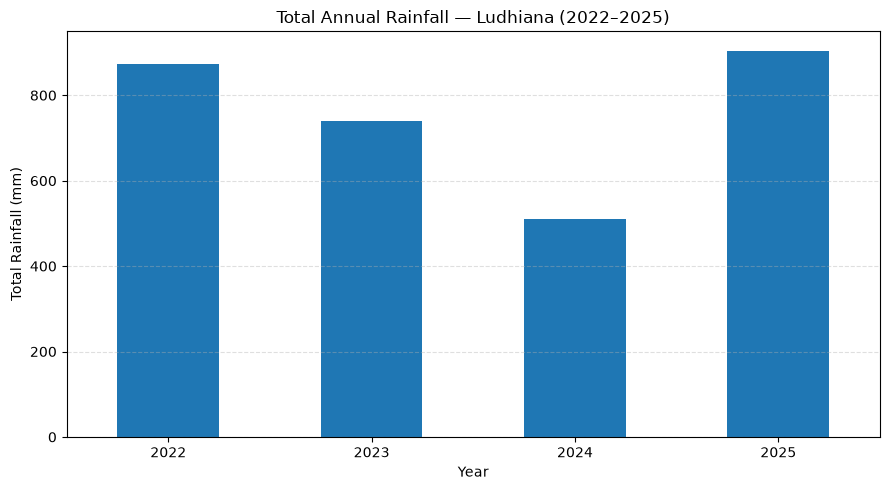

In [7]:

# STEP 52 — Analyze yearly rainfall trends

analysis_df["year"] = analysis_df["date"].dt.year

yearly_rainfall = analysis_df.groupby("year").agg(
    total_rainfall_mm=("observed_rainfall_mm", "sum"),
    average_daily_rainfall_mm=("observed_rainfall_mm", "mean"),
    rainy_days=("observed_rainfall_mm", lambda values: (values >= 0.1).sum())
)

print("YEARLY RAINFALL ANALYSIS")
print("-" * 45)
print(yearly_rainfall.round(2).to_string())

plt.figure(figsize=(9, 5))
yearly_rainfall["total_rainfall_mm"].plot(kind="bar")

plt.title("Total Annual Rainfall — Ludhiana (2022–2025)")
plt.xlabel("Year")
plt.ylabel("Total Rainfall (mm)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


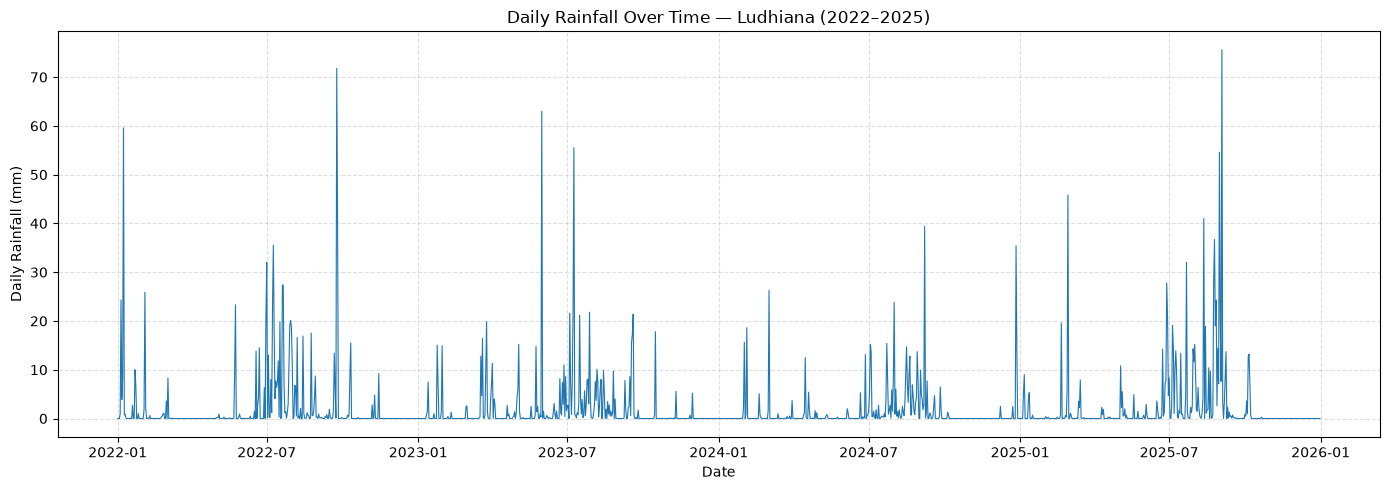

Highest daily rainfall: 75.6 mm
Number of days with rainfall >= 20 mm: 35


In [8]:

# STEP 53 — Plot daily rainfall over time

plt.figure(figsize=(14, 5))

plt.plot(
    analysis_df["date"],
    analysis_df["observed_rainfall_mm"],
    linewidth=0.8
)

plt.title("Daily Rainfall Over Time — Ludhiana (2022–2025)")
plt.xlabel("Date")
plt.ylabel("Daily Rainfall (mm)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Highest daily rainfall:",
      analysis_df["observed_rainfall_mm"].max(), "mm")

print("Number of days with rainfall >= 20 mm:",
      (analysis_df["observed_rainfall_mm"] >= 20).sum())


SEASONAL RAINFALL ANALYSIS
---------------------------------------------
              average_daily_rainfall_mm  total_rainfall_mm  rainy_days
season                                                                
Winter                             1.11              401.8          61
Summer                             1.03              379.3          95
Monsoon                            4.37             2131.4         336
Post-Monsoon                       0.48              115.9          29


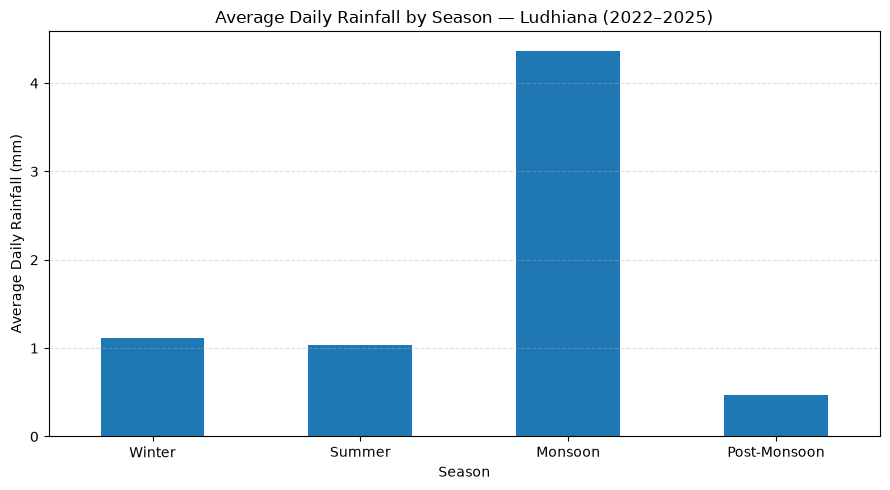

In [9]:

# STEP 54 — Analyze rainfall by season

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

analysis_df["season"] = analysis_df["date"].dt.month.apply(get_season)

season_order = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]

seasonal_rainfall = analysis_df.groupby("season").agg(
    average_daily_rainfall_mm=("observed_rainfall_mm", "mean"),
    total_rainfall_mm=("observed_rainfall_mm", "sum"),
    rainy_days=("observed_rainfall_mm", lambda values: (values >= 0.1).sum())
).reindex(season_order)

print("SEASONAL RAINFALL ANALYSIS")
print("-" * 45)
print(seasonal_rainfall.round(2).to_string())

plt.figure(figsize=(9, 5))
seasonal_rainfall["average_daily_rainfall_mm"].plot(kind="bar")

plt.title("Average Daily Rainfall by Season — Ludhiana (2022–2025)")
plt.xlabel("Season")
plt.ylabel("Average Daily Rainfall (mm)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [10]:

# STEP 55 — Find the wettest and driest dates

wettest_index = analysis_df["observed_rainfall_mm"].idxmax()
driest_index = analysis_df["observed_rainfall_mm"].idxmin()

print("WETTEST DAY")
print("Date:", analysis_df.loc[wettest_index, "date"].date())
print("Rainfall:", analysis_df.loc[wettest_index, "observed_rainfall_mm"], "mm")

print("\nDRIEST DAY")
print("Date:", analysis_df.loc[driest_index, "date"].date())
print("Rainfall:", analysis_df.loc[driest_index, "observed_rainfall_mm"], "mm")


WETTEST DAY
Date: 2025-09-03
Rainfall: 75.6 mm

DRIEST DAY
Date: 2022-01-01
Rainfall: 0.0 mm


In [11]:

# STEP 56 — Find consecutive dry periods

dry_mask = analysis_df["observed_rainfall_mm"] < 0.1
dry_group = (~dry_mask).cumsum()

dry_streaks = (
    analysis_df.loc[dry_mask]
    .assign(streak_group=dry_group[dry_mask].values)
    .groupby("streak_group")
    .agg(
        days=("date", "size"),
        start_date=("date", "min"),
        end_date=("date", "max")
    )
)

if not dry_streaks.empty:
    longest_dry = dry_streaks.loc[dry_streaks["days"].idxmax()]
    print("LONGEST CONSECUTIVE DRY PERIOD")
    print("Days:", int(longest_dry["days"]))
    print("Start:", longest_dry["start_date"].date())
    print("End:", longest_dry["end_date"].date())
else:
    print("No dry days found.")


LONGEST CONSECUTIVE DRY PERIOD
Days: 71
Start: 2025-10-22
End: 2025-12-31


7-DAY RAINFALL ANALYSIS
-----------------------------------
Average 7-day rainfall: 14.53 mm
Maximum 7-day rainfall: 182.6 mm


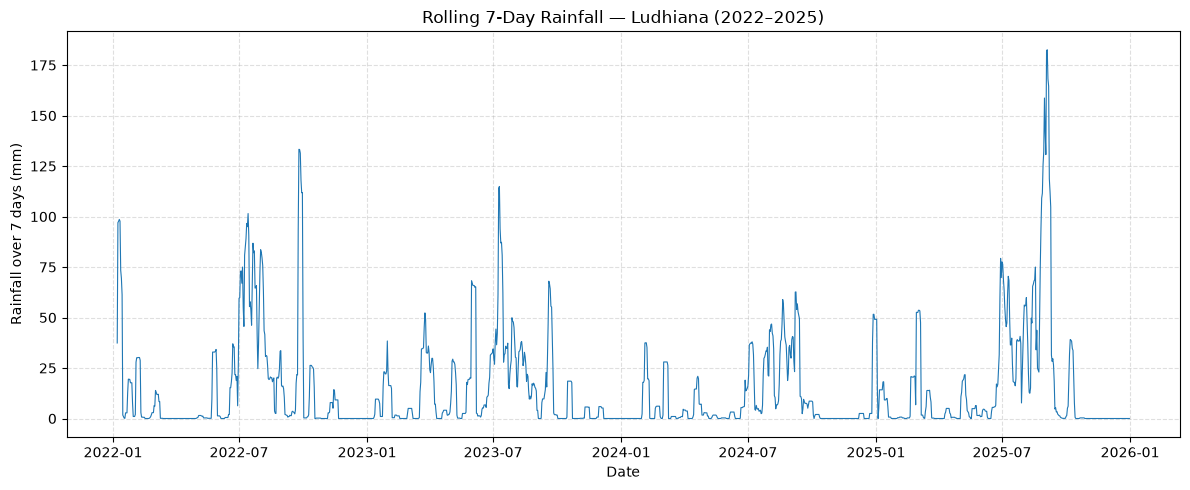

In [12]:

# STEP 57 — Calculate rolling 7-day rainfall

analysis_df["rainfall_7day_total_mm"] = (
    analysis_df["observed_rainfall_mm"].rolling(window=7).sum()
)

print("7-DAY RAINFALL ANALYSIS")
print("-" * 35)
print("Average 7-day rainfall:",
      round(analysis_df["rainfall_7day_total_mm"].mean(), 2), "mm")
print("Maximum 7-day rainfall:",
      round(analysis_df["rainfall_7day_total_mm"].max(), 2), "mm")

plt.figure(figsize=(12, 5))
plt.plot(
    analysis_df["date"],
    analysis_df["rainfall_7day_total_mm"],
    linewidth=0.8
)
plt.title("Rolling 7-Day Rainfall — Ludhiana (2022–2025)")
plt.xlabel("Date")
plt.ylabel("Rainfall over 7 days (mm)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [13]:

# STEP 58 — Check data quality

analysis_df = analysis_df.sort_values("date").reset_index(drop=True)

print("DATA QUALITY REPORT")
print("-" * 35)
print("Total rows:", len(analysis_df))
print("Missing values:", int(analysis_df.isna().sum().sum()))
print("Duplicate dates:", int(analysis_df["date"].duplicated().sum()))
print("Negative rainfall values:",
      int((analysis_df["observed_rainfall_mm"] < 0).sum()))

date_gaps = analysis_df["date"].diff().dt.days
print("Gaps greater than one day:",
      int((date_gaps > 1).sum()))

print("First date:", analysis_df["date"].min().date())
print("Last date:", analysis_df["date"].max().date())


DATA QUALITY REPORT
-----------------------------------
Total rows: 1461
Missing values: 6
Duplicate dates: 0
Negative rainfall values: 0
Gaps greater than one day: 0
First date: 2022-01-01
Last date: 2025-12-31


In [14]:

# STEP 59 — Monthly rainfall summary

analysis_df["year_month"] = analysis_df["date"].dt.to_period("M")

monthly_summary = analysis_df.groupby("year_month").agg(
    total_rainfall_mm=("observed_rainfall_mm", "sum"),
    average_daily_rainfall_mm=("observed_rainfall_mm", "mean"),
    rainy_days=("observed_rainfall_mm", lambda values: (values >= 0.1).sum()),
    maximum_daily_rainfall_mm=("observed_rainfall_mm", "max")
)

print("MONTHLY SUMMARY — FIRST 12 MONTHS")
print(monthly_summary.head(12).round(2).to_string())

print("\nWettest month in the dataset:")
print(monthly_summary["total_rainfall_mm"].idxmax())

print("Highest monthly total:",
      round(monthly_summary["total_rainfall_mm"].max(), 2), "mm")


MONTHLY SUMMARY — FIRST 12 MONTHS
            total_rainfall_mm  average_daily_rainfall_mm  rainy_days  maximum_daily_rainfall_mm
year_month                                                                                     
2022-01                 119.2                       3.85          13                       59.6
2022-02                  33.7                       1.20          10                       25.9
2022-03                  12.0                       0.39           3                        8.3
2022-04                   0.0                       0.00           0                        0.0
2022-05                  36.1                       1.16          10                       23.3
2022-06                  65.1                       2.17           8                       21.3
2022-07                 325.6                      10.50          30                       35.5
2022-08                  98.8                       3.19          24                       17.5
2022-0

In [15]:

# STEP 60 — Save analysis outputs

from pathlib import Path

output_dir = Path("../data/processed")
if not output_dir.exists():
    output_dir = Path("data/processed")

output_dir.mkdir(parents=True, exist_ok=True)

monthly_summary.to_csv(output_dir / "ludhiana_monthly_rainfall_summary.csv")

seasonal_rainfall.to_csv(output_dir / "ludhiana_seasonal_rainfall_summary.csv")

analysis_df.to_csv(
    output_dir / "ludhiana_rainfall_analysis_2022_2025.csv",
    index=False
)

print("ANALYSIS FILES SAVED SUCCESSFULLY")
print("-" * 40)
print("Folder:", output_dir.resolve())
print("1. ludhiana_monthly_rainfall_summary.csv")
print("2. ludhiana_seasonal_rainfall_summary.csv")
print("3. ludhiana_rainfall_analysis_2022_2025.csv")


ANALYSIS FILES SAVED SUCCESSFULLY
----------------------------------------
Folder: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed
1. ludhiana_monthly_rainfall_summary.csv
2. ludhiana_seasonal_rainfall_summary.csv
3. ludhiana_rainfall_analysis_2022_2025.csv
